# Lab 13: Comparing ECCO and OSCAR Surface Velocities

In this lab, we will compare sea surface velocity data from two sources: 1) an ocean state estimate from the Estimating the Circulation and Climate of the Ocean consortium and 2) the Ocean Surface Current Analyses Real-time (OSCAR) product derived from remotely-sensed data. We will see how to compare these products both in space and in time.

This notebook has four main parts organized as follows:

1. Downloading ECCO and OSCAR surface velocity data
2. Interpolating ECCO onto the OSCAR grid
3. Spatial comparison between model and data
4. Temporal comparison between model and data

**Import the modules for this notebook**

In [1]:
# import the modules used in previous notebooks
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import netCDF4 as nc4

# import the data access tools
from subscriber import podaac_data_downloader as pdd
import earthaccess

# import the interpolation tool
from scipy.interpolate import griddata

# import the modules for geographic plots
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean.cm as cm

## Motivation

In the previous labs, we have explored several satellite-derived products. In each case, we were primarily working with observations or observation-based analyses. Oceanographers also use numerical models to reconstruct the ocean circulation, and we often want to compare the model with observations to understand where the model is consistent with observations.

### ECCO State Estimate

In this lab, we will work with the Estimating the Circulation and Climate of the Ocean (ECCO) Version 4 Release 4 state estimate. ECCO state estimates are based on a global configuration of the MIT General Circulation Model (MITgcm). The model uses a large collection of satellite and in situ observations to construct a dynamically consistent reconstruction of the three-dimensional, time-evolving ocean state, but there are nonetheless differences between these observations and the modeled state.

### OSCAR Ocean Currents

We will compare daily surface velocities from ECCO with daily surface currents from the Ocean Surface Current Analyses Real-time (OSCAR) product. OSCAR is an observation-based surface-current analysis that combines satellite sea-surface height, surface wind, and sea-surface-temperature information using a simplified physical model.

### An Example: Ocean Circulation in the 2015 El Niño Event

In this lab, we will explore one month in the year 2015 when a strong El Niño event modulated ocean properties in the equatorial Pacific. We will examine the extent to which the surface circulation is influenced by the changes due to ENSO conditions. This type of comparison is common to test model-data consistency but it is important to note that it is not a completely independent validation since ECCO and OSCAR use some overlapping observing systems, including satellite observations of the sea surface.

## Getting Started

As in the previous labs, we will keep the downloaded files in a separate data directory. We will divide the data into two subdirectories so that it is easy to tell which files came from ECCO and which came from OSCAR. Define a path to your data folder and ensure you have some folders for the individual products:

In [2]:
# define the path to the data folder for this lab
data_folder = '../data/labs/lab13'

# make separate folders for the two data products
ecco_folder = os.path.join(data_folder, 'ecco')
oscar_folder = os.path.join(data_folder, 'oscar')
os.makedirs(ecco_folder, exist_ok=True)
os.makedirs(oscar_folder, exist_ok=True)

## Part 1: Downloading ECCO and OSCAR surface velocity data

To download the products for this lab, begin by defining the time span of interest:

In [3]:
# define the year used in the lab
year = 2015

# define the beginning and end of the time interval
start_date_time = str(year)+'-12-01T00:00:00Z'
end_date_time = str(year)+'-12-31T23:59:59Z'

### Downloading the ECCO Data

To obtain the ECCO Version 4 Release 4 state estimate, we will use the product available on the Physical Oceanography DAAC. A description of the ECCO velocity is available [HERE](https://cmr.earthdata.nasa.gov/search/concepts/C1990404811-POCLOUD.html). We can download this data using the `podaac-data-subscriber` tools as we saw in [Lab 6](https://profmikewood.github.io/ocean_remote_sensing_book/lab06-sss-timeseries/).

Recall that we need to provide a collection short name:

In [4]:
# define the collection name
collection_short_name = 'ECCO_L4_OCEAN_VEL_05DEG_DAILY_V4R4'

Then, we can use the PODAAC tools to obtain the data:

In [5]:
# create the downloader arguments
parser = pdd.create_parser()
args = parser.parse_args([
    '-c', collection_short_name,
    '-d', ecco_folder,
    '-sd', start_date_time,
    '-ed', end_date_time,
    '--verbose'
])
pdd.run(args)

After downloading the files, we can ensure that we have all of the files in the month:

In [6]:
# make a list of ecco files
ecco_files = []
for file_name in sorted(os.listdir(ecco_folder)):
    if file_name.endswith(('.nc')) and not file_name.startswith('.'):
        ecco_files.append(os.path.join(ecco_folder, file_name))

print('Found', len(ecco_files), 'ECCO NetCDF files')

Found 32 ECCO NetCDF files


### Downloading the OSCAR data

Next, we will download the OSCAR data. We will use the 0.25 degree product described [HERE](https://www.earthdata.nasa.gov/data/catalog/pocloud-oscar-l4-oc-final-v2.0-2.0). This data set is available using `earthaccess` with the tools introduced during [lab 8](https://profmikewood.github.io/ocean_remote_sensing_book/lab08-wind-figures/).

Recall that we need to "log in" to Earthdata with our stored credentials:

In [7]:
# log in to NASA Earthdata
earthaccess.login();

Next, we search for granules using a search function:

In [8]:
# Search for all granules in the time range
granules = earthaccess.search_data(
    short_name="OSCAR_L4_OC_FINAL_V2.0",
    version="2.0",
    provider="POCLOUD",
    temporal=(
        start_date_time,
        end_date_time,
    ),
    count=-1,              # retrieve all matching granules
    downloadable=True,
)

print(f"Found {len(granules)} granules.")

Found 31 granules.


Finally, we download the files with a download function:

In [9]:
# Download files, skipping files already present.
oscar_files = earthaccess.download(
    granules,
    local_path=oscar_folder,
    threads=4,
    force=False,
)
print(f"Downloaded {len(oscar_files)} files.")

QUEUEING TASKS | :   0%|          | 0/31 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/31 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/31 [00:00<?, ?it/s]

Downloaded 31 files.


### Inspecting files from each product

#### Examine the variables in Panoply

Before writing a loop over many daily files in our analysis, it is useful to open one file and examine its variables. Pop these open in Panoply and examine the variable names, dimensions, units, and coordinate conventions.

#### Plot the first ECCO surface velocity

Using the information observed in Panoply, next we'll write a Python function to read in the surface grid of the ECCO product. The function should take in a file path and return a 2D grid of velocity.

In [10]:
def read_ecco_surface(file_path):
    # open the daily ECCO file
    ds = nc4.Dataset(file_path)

    # read the geographic and coordinates
    longitude = ds.variables['longitude'][:]
    latitude = ds.variables['latitude'][:]

    # read the eastward and northward velocity components
    eastward_velocity = ds.variables['EVEL'][0, 0, :, :]
    northward_velocity = ds.variables['NVEL'][0, 0, :, :]

    ds.close()

    return (longitude, latitude,
            eastward_velocity, northward_velocity)

Using the function above, let's plot the first field to see how it looks:

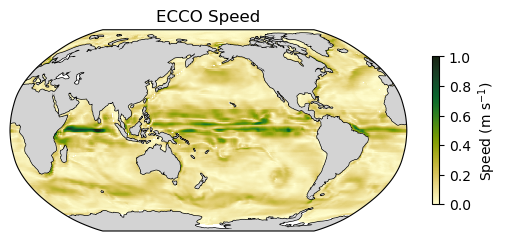

In [11]:
# read the first file 
ecco_lon, ecco_lat, ecco_u, ecco_v \
    = read_ecco_surface(ecco_files[0])

# make a figure showing the speed
fig = plt.figure()
ax = plt.axes(projection=ccrs.Robinson(central_longitude=-180))

ecco_speed = (ecco_u**2 + ecco_v**2)**0.5
C = ax.pcolormesh(ecco_lon, ecco_lat, ecco_speed,
                  cmap=cm.speed, vmin=0, vmax=1.0,
                  transform=ccrs.PlateCarree())

ax.add_feature(cfeature.LAND, facecolor='lightgray', zorder=2)
ax.coastlines()
ax.set_title('ECCO Speed')

plt.colorbar(C, label='Speed (m s$^{-1}$)', shrink=0.4)
plt.show()

#### Plot the first OSCAR surface velocity

Similar to the steps for the ECCO data above, next we'll write a Python function to read in the velocities from the OSCAR product. Again, the function should take in a file path and return a 2D grid of velocity.

In [12]:
# make the function to read oscar surface velocity here
def read_oscar_surface(file_path):
    # open the daily OSCAR file
    ds = nc4.Dataset(file_path)

    # read in the geographic variables
    longitude = ds.variables['lon'][:]
    latitude = ds.variables['lat'][:]

    # OSCAR is stored as (time, longitude, latitude)
    eastward_velocity = ds.variables['u'][0,:,:]
    northward_velocity = ds.variables['v'][0,:,:]

    # transpose to (latitude, longitude)
    eastward_velocity = eastward_velocity.T
    northward_velocity = northward_velocity.T

    ds.close()

    return longitude, latitude, eastward_velocity, northward_velocity

Again, using the function above, let's plot the first field to see how it looks:

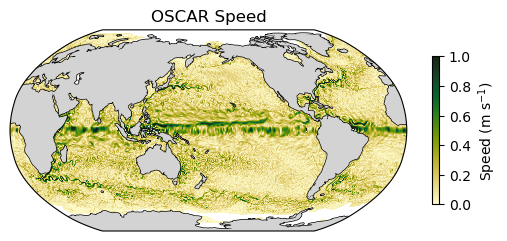

In [13]:
# read the first file 
oscar_lon, oscar_lat, oscar_u, oscar_v \
    = read_oscar_surface(oscar_files[0])

# make a figure showing the speed
fig = plt.figure()
ax = plt.axes(projection=ccrs.Robinson(central_longitude=-180))

oscar_speed = (oscar_u**2 + oscar_v**2)**0.5
C = ax.pcolormesh(oscar_lon, oscar_lat, oscar_speed,
                  cmap=cm.speed, vmin=0, vmax=1.0,
                  transform=ccrs.PlateCarree())

ax.add_feature(cfeature.LAND, facecolor='lightgray', zorder=2)
ax.coastlines()
ax.set_title('OSCAR Speed')

plt.colorbar(C, label='Speed (m s$^{-1}$)', shrink=0.4)
plt.show()

## Part 2: Interpolating ECCO velocities onto the OSCAR grid

The ECCO model output is posted on a grid with a 0.5-degree spacing, while the OSCAR grid has 0.25-degree spacing. A direct subtraction such as `ecco_u - oscar_u` will not work unless the arrays have the same shape and represent the same geographic locations. 

In this section, we will use linear interpolation to estimate the ECCO velocity at every OSCAR grid cell center. We will interpolate the eastward and northward components separately. After this step, we will obtain `ecco_u_on_oscar` and `ecco_v_on_oscar` fields with the same dimensions and coordinates as the
OSCAR fields.

### Read in all ECCO and OSCAR data

To facilitate this interpolation at each of the grid points in our study time period, let's first use the functions above to read in the ECCO data and the OSCAR data into 3D arrays containing the fields for each of the files. Let's start with the ECCO data:

In [14]:
# allocate arrays for the complete ECCO time series
n_days = 31
ecco_U = np.zeros((n_days, len(ecco_lat), len(ecco_lon)))
ecco_V = np.zeros((n_days, len(ecco_lat), len(ecco_lon)))

# loop through each day
for day in range(1,n_days+1):
    # read in the data
    file_name = 'OCEAN_VELOCITY_day_mean_2015-12-'+'{:02d}'.format(day)+'_ECCO_V4r4_latlon_0p50deg.nc'
    file_path = os.path.join(ecco_folder, file_name)
    ecco_lon, ecco_lat, ecco_u, ecco_v \
        = read_ecco_surface(file_path)

    # add the data to the grids
    ecco_U[day-1,:,:] = ecco_u
    ecco_V[day-1,:,:] = ecco_v

print('ECCO array shape:', ecco_U.shape)

ECCO array shape: (31, 360, 720)


Next, let's read in the OSCAR data:

In [15]:
# allocate arrays for the complete OSCAR time series
n_days = 31
oscar_U = np.zeros((n_days, len(oscar_lat), len(oscar_lon)))
oscar_V = np.zeros((n_days, len(oscar_lat), len(oscar_lon)))

# loop through each day
for day in range(1,n_days+1):
    # read in the data
    file_name = 'oscar_currents_final_201512'+'{:02d}'.format(day)+'.nc'
    file_path = os.path.join(oscar_folder, file_name)
    oscar_lon, oscar_lat, oscar_u, oscar_v \
        = read_oscar_surface(file_path)

    # add the data to the grids
    oscar_U[day-1,:,:] = oscar_u
    oscar_V[day-1,:,:] = oscar_v

print('OSCAR array shape:', oscar_U.shape)

OSCAR array shape: (31, 719, 1440)


### Interpolate ECCO Data to the OSCAR grid

Next, we'll write a function to interpolate each 2D ECCO field onto the OSCAR grid. Then we'll use this function in a loop to make new ECCO grids which are the same shape as the OSCAR grid with the data at co-located regions.

```{warning}
When interpolating with geographic coordinates expressed as longitude and latitude, there are two things to keep in mind. First, beware that some files have longitude values expressed in the range [-180,180] while others have longitude expressed in [0, 360]. These values must be identical for an accurate interpolation. Second, the distances will be distorted at the poles since longitude and latitude do not represent the same distances at these locations. We will assume the distances are approximately equal near the equator and accept errors in the interpolation for this example. If you are working on an analysis near the poles, you would want to reproject your coordinate system to something more appropriate for the polar regions before the interpolation.
```

Write the interpolation function below (hint: reference the [interpolation in Lab 9](https://profmikewood.github.io/ocean_remote_sensing_book/lab10-swot-pace/#interpolating-pace-data-onto-the-transect) if you need a reminder for how this works):

In [16]:
# write a function to interpolate an ecco field to the oscar grid provided
# both sets of longitude and latitude arrays and the ecco field
def interpolate_to_grid(source_latitude, source_longitude, source_field,
                        target_latitude, target_longitude):

    # make an array of longitude/latitude source points
    source_Longitude, source_Latitude = \
        np.meshgrid(source_longitude,source_latitude)

    # convert longitudes to the correct zone
    source_Longitude[source_Longitude<0]+=360

    # make an (N,2) array of source points
    source_points = np.column_stack((
        source_Longitude.ravel(),
        source_Latitude.ravel()))

    # make an array of longitude/latitude target points
    target_Longitude, target_Latitude = \
        np.meshgrid(target_longitude, target_latitude)

    # run the interpolation
    interpolated_field = griddata(
        source_points, source_field.ravel(),
        (target_Longitude, target_Latitude))

    return interpolated_field

The interpolation function above works on one two-dimensional field. We will now apply it to each daily ECCO field so that the resulting model arrays are stored on the OSCAR grid (but they still represent ECCO velocities).

In [17]:
# allocate ECCO arrays on the OSCAR grid
ecco_U_on_oscar = np.zeros((n_days, len(oscar_lat), len(oscar_lon)))
ecco_V_on_oscar = np.zeros((n_days, len(oscar_lat), len(oscar_lon)))

# interpolate the ECCO fields for each common day
for day in range(1,n_days+1):
    # print(' - Interpolating conditions on day '+str(day))
    ecco_U_on_oscar[day-1, :, :] = interpolate_to_grid(
        ecco_lat, ecco_lon, ecco_U[day-1, :, :],
        oscar_lat, oscar_lon
    )
    ecco_V_on_oscar[day-1, :, :] = interpolate_to_grid(
        ecco_lat, ecco_lon, ecco_V[day-1, :, :],
        oscar_lat, oscar_lon
    )

### Plot the interpolation result

Now that the ECCO data is on the same grid as the OSCAR data, let's plot the pre- and post-interpolation grids to ensure the process was carried out as expected. First, let's compute the speeds for each product on the first time step:

In [18]:
# compute the ecco speed on the first time step
ecco_speed = (ecco_U[0, :, :]**2 + ecco_V[0, :, :]**2)**0.5
ecco_speed = np.ma.masked_where(ecco_speed>1e4,ecco_speed)

# compute the interpolated speed on the first time step
interpolated_ecco_speed = (ecco_U_on_oscar[0, :, :]**2 + 
                           ecco_V_on_oscar[0, :, :]**2)**0.5
interpolated_ecco_speed = np.ma.masked_where(interpolated_ecco_speed>1e4,interpolated_ecco_speed)

Then, plot the two side-by-side

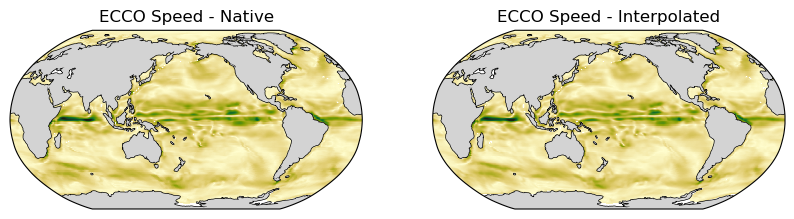

In [19]:
# make a figure object
fig = plt.figure(figsize=(10, 4))

# plot the native ECCO speed
plt.subplot(1,2,1, projection=ccrs.Robinson(central_longitude=-180))
C = plt.pcolormesh(
    ecco_lon, ecco_lat, ecco_speed,
    cmap=cm.speed, vmin=0, vmax=1.0,
    transform=ccrs.PlateCarree()
)
plt.gca().add_feature(cfeature.LAND, facecolor='lightgray', zorder=2)
plt.gca().coastlines()
plt.title('ECCO Speed - Native')

# plot the interpolated ECCO speed
plt.subplot(1,2,2, projection=ccrs.Robinson(central_longitude=-180))
C = plt.pcolormesh(
    oscar_lon, oscar_lat, interpolated_ecco_speed,
    cmap=cm.speed, vmin=0, vmax=1.0,
    transform=ccrs.PlateCarree()
)
plt.gca().add_feature(cfeature.LAND, facecolor='lightgray', zorder=2)
plt.gca().coastlines()
plt.title('ECCO Speed - Interpolated')

plt.show()

### 🤔 Consider these questions

- Why do the native ECCO and interpolated ECCO fields look similar but not identical?
- What information is added by interpolating the model rather than simply resizing the array?
- Where might linear interpolation produce misleading values?
- If we instead interpolated OSCAR onto the ECCO grid, would the model-data comparison be the same?

## Part 3: Spatial comparison between model and data 

Now the model and observation-based product have matching dates and matching grid-cell centers, we can compare the products cell by cell.

### Mean Speed Comparison
One of the first metrics we can compare is the mean speed fields - this will give us a broad sense for where the model is consistent with the data. Begin by computing the mean through time:

In [20]:
# compute the mean speed of the interpolated ecco data
interpolated_ecco_speed = (ecco_U_on_oscar**2 + 
                           ecco_V_on_oscar**2)**0.5
mean_interpolated_ecco_speed = np.mean(interpolated_ecco_speed, axis=0)
mean_interpolated_ecco_speed = np.ma.masked_where(mean_interpolated_ecco_speed>1e4,
                                                  mean_interpolated_ecco_speed)

# compute the mean speed of the oscar data
oscar_speed = (oscar_U**2 + oscar_V**2)**0.5
mean_oscar_speed = np.mean(oscar_speed, axis=0)
mean_oscar_speed = np.ma.masked_where(mean_oscar_speed>100,
                                      mean_oscar_speed)

Then, plot these means along with their difference:

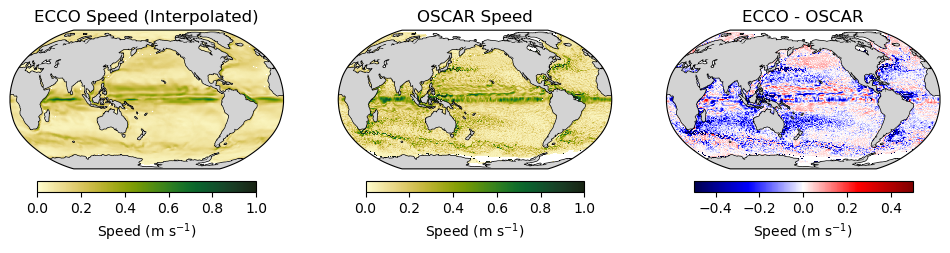

In [21]:
fig = plt.figure(figsize=(12, 4))

# plot the mean interpolated ECCO speed
plt.subplot(1,3,1, projection=ccrs.Robinson(central_longitude=-180))
C = plt.pcolormesh(
    oscar_lon, oscar_lat, mean_interpolated_ecco_speed,
    cmap=cm.speed, vmin=0, vmax=1.0,
    transform=ccrs.PlateCarree()
)
plt.gca().add_feature(cfeature.LAND, facecolor='lightgray', zorder=2)
plt.gca().coastlines()
plt.title('ECCO Speed (Interpolated)')
plt.colorbar(C, label='Speed (m s$^{-1}$)', shrink=0.8,
             orientation='horizontal', pad=0.04)

# plot the mean OSCAR speed
plt.subplot(1,3,2, projection=ccrs.Robinson(central_longitude=-180))
C = plt.pcolormesh(
    oscar_lon, oscar_lat, mean_oscar_speed,
    cmap=cm.speed, vmin=0, vmax=1.0,
    transform=ccrs.PlateCarree()
)
plt.gca().add_feature(cfeature.LAND, facecolor='lightgray', zorder=2)
plt.gca().coastlines()
plt.title('OSCAR Speed')
plt.colorbar(C, label='Speed (m s$^{-1}$)', shrink=0.8,
             orientation='horizontal', pad=0.04)

# plot the mean ECCO - OSCAR speed difference
plt.subplot(1,3,3, projection=ccrs.Robinson(central_longitude=-180))
C = plt.pcolormesh(
    oscar_lon, oscar_lat, mean_interpolated_ecco_speed - mean_oscar_speed,
    cmap='seismic', vmin=-0.5, vmax=0.5,
    transform=ccrs.PlateCarree()
)
plt.gca().add_feature(cfeature.LAND, facecolor='lightgray', zorder=2)
plt.gca().coastlines()
plt.title('ECCO - OSCAR')
plt.colorbar(C, label='Speed (m s$^{-1}$)', shrink=0.8,
             orientation='horizontal', pad=0.04)

plt.show()

#### Comparison as a scatter plot 
Another way that we can compare speeds in the model and the observational product is through a scatter plot. Begin by making two arrays with the mean interpolated ECCO points and the OSCAR points. Be sure to remove masked values and ensure that both arrays are the same size

In [22]:
# make a set of co-located points
colocated_points = np.column_stack([mean_interpolated_ecco_speed.ravel(),
                                    mean_oscar_speed.ravel()])

# remove nonsense values
colocated_points = colocated_points[colocated_points[:,0]<10,:]
colocated_points = colocated_points[colocated_points[:,1]<10,:]

Then, make a scatter plot with a one-to-one line:

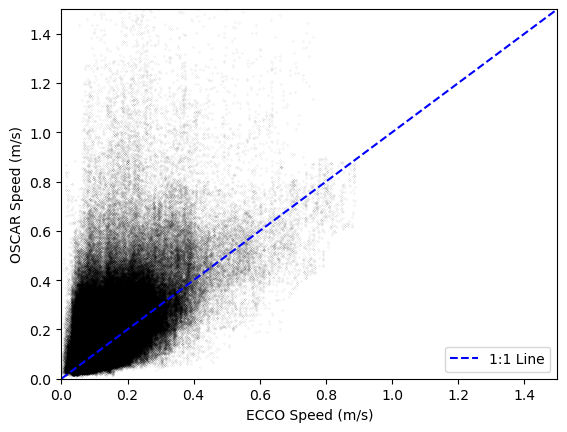

In [23]:
# make a figure object
fig = plt.figure()

# plot the scatter of points
plt.plot(colocated_points[:,0], colocated_points[:,1], 'k.',
         markersize=0.1, alpha=0.8)

# plot the one to one line
plt.plot([0,1.5],[0,1.5],'b--', label='1:1 Line')

# format the axes
plt.xlim(0,1.5)
plt.ylim(0,1.5)
plt.ylabel('OSCAR Speed (m/s)')
plt.xlabel('ECCO Speed (m/s)')
plt.legend()

# show the plot
plt.show()

### 🤔 Consider these questions

- Is the mean speed larger in ECCO or OSCAR? 
- Does the model-data difference have a preferred sign or a preferred location?
- What leads to these differences?

## Part 4: Temporal comparison between model and data

In addition to spatial comparisons, we can also examine how the model and data values change through time. This comparison can reveal short term variability, unusual events, and periods when the model-data mismatch becomes larger.

In this example, we'll compare the daily mean zonal and meridional velocity in the equatorial region of the Pacific. To begin, let's define a mask defined by longitudes and latitudes around the equatorial Pacific:


In [24]:
# define some longitude/latitude bounds for the region of interest
min_lon = 160
max_lon = 260
min_lat = -5
max_lat = 5

# make the mask
oscar_Lon, oscar_Lat = np.meshgrid(oscar_lon, oscar_lat)
equatorial_Pacific_mask = np.logical_and(np.logical_and(oscar_Lon>=min_lon, oscar_Lon<=max_lon),
                                         np.logical_and(oscar_Lat>=min_lat, oscar_Lat<=max_lat))

Let's make sure this mask is located on the map where we anticipate it should be located - always good to do a sanity check:

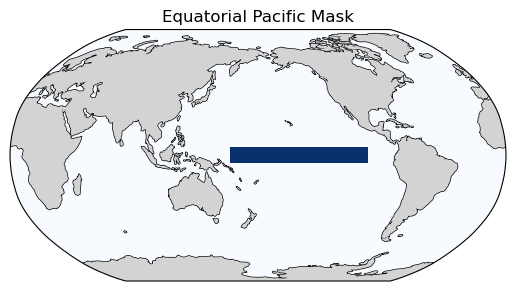

In [25]:
# make a figure object
plt.figure()

# make a plot of the mask
plt.subplot(1,1,1, projection=ccrs.Robinson(central_longitude=-180))
C = plt.pcolormesh(
    oscar_lon, oscar_lat, equatorial_Pacific_mask,
    cmap='Blues', vmin=0, vmax=1,
    transform=ccrs.PlateCarree()
)
plt.gca().add_feature(cfeature.LAND, facecolor='lightgray', zorder=2)
plt.gca().coastlines()
plt.title('Equatorial Pacific Mask')

plt.show()

When we're happy with the mask, we can compute statistics in this mask. Let's compute a daily time series of zonal and meridional velocities in this mask area:

In [26]:
# make empty arrays to hold the velocity time series
ecco_u_pacific = np.zeros((n_days,))
ecco_v_pacific = np.zeros((n_days,))
oscar_u_pacific = np.zeros((n_days,))
oscar_v_pacific = np.zeros((n_days,))

# fill in the time series with the mean (masked) velocities on each day
for day in range(1,n_days+1):
    ecco_u_pacific[day-1] = np.nanmean(ecco_U_on_oscar[day-1,:,:][equatorial_Pacific_mask])
    ecco_v_pacific[day-1] = np.nanmean(ecco_V_on_oscar[day-1,:,:][equatorial_Pacific_mask])
    oscar_u_pacific[day-1] = np.nanmean(oscar_U[day-1,:,:][equatorial_Pacific_mask])
    oscar_v_pacific[day-1] = np.nanmean(oscar_V[day-1,:,:][equatorial_Pacific_mask])

Finally, let's plot these time series for comparison:

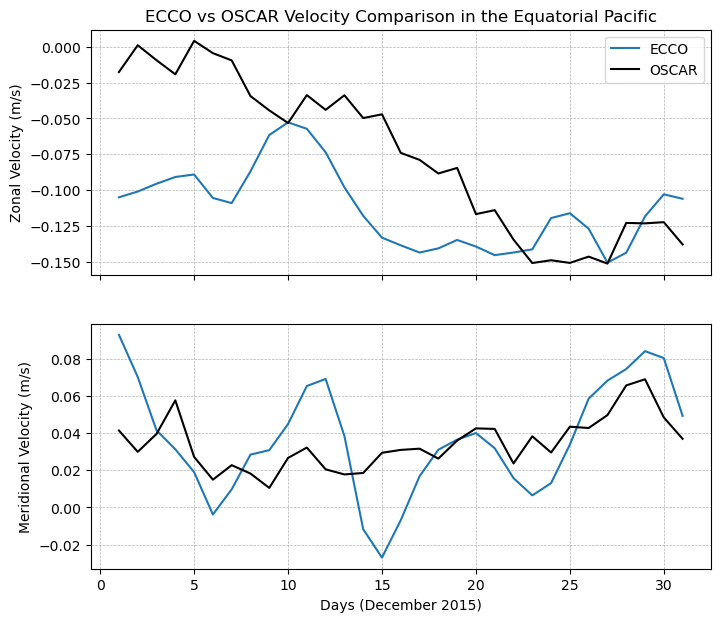

In [27]:
plt.figure(figsize=(8,7))

# plot the zonal velocity comparison
plt.subplot(2,1,1)
plt.plot(np.arange(1,n_days+1),ecco_u_pacific,label='ECCO')
plt.plot(np.arange(1,n_days+1),oscar_u_pacific,'k-',label='OSCAR')
plt.gca().set_xticklabels([])
plt.grid(linestyle='--',linewidth=0.5)
plt.ylabel('Zonal Velocity (m/s)')
plt.legend()
plt.title('ECCO vs OSCAR Velocity Comparison in the Equatorial Pacific')

# plot the meridional velocity comparison
plt.subplot(2,1,2)
plt.plot(np.arange(1,n_days+1),ecco_v_pacific)
plt.plot(np.arange(1,n_days+1),oscar_v_pacific,'k-')
plt.grid(linestyle='--',linewidth=0.5)
plt.xlabel('Days (December 2015)')
plt.ylabel('Meridional Velocity (m/s)')

plt.show()

### 🤔 Consider these questions

- How do the mean velocities compare through this month?
- How does this influence your interpretation of each product?

## 🤔 Try it for yourself!

Try this same comparison for another time period and region of interest. How do your results compare to the analysis here?